# H6 – La capacité d'achat améliore-t-elle la prévision au-delà du modèle pont ?
**Contributeur :** Théophyle · **Date :** 10/11/2026

Notebook construit à partir du template commun et du gabarit du modèle pont (`gabarit_pont.py`). Tout ce qui doit être identique d'une hypothèse à l'autre passe par `commun.py` : la table, le masque, les fenêtres, la naïve, `evaluer` et `tester`.

**Question :** un territoire où acheter coûte cher par rapport aux revenus voit-il son prix monter moins vite (ou baisser) ? Si oui, la capacité d'achat doit améliorer la prévision **au-delà du modèle pont**.

**L'indicateur (P7) :** le **taux d'effort** = mensualité d'un crédit / revenu mensuel × 100.
- Crédit : 100 % du prix, 25 ans, taux moyen de la Banque de France de décembre N-1, pour 60 m² (appartement) ou 100 m² (maison) au prix N-1 du sous-bassin.
- Revenu : niveau de vie médian du sous-bassin (Filosofi) × 1,5 unité de consommation / 12.
- Exemple (P7) : sous-bassin 56240, appartement à 4 646 €/m², taux 3,63 % : mensualité 2 358 €, revenu 3 365 € par mois, taux d'effort 70 %. Un ménage médian ne peut pas acheter.

**Ce que le taux d'effort ajoute au pont (à garder en tête pour toute la lecture).** Le pont contient déjà le prix N-1. En log, le taux d'effort se découpe en trois morceaux :

log(taux d'effort) = log(prix N-1) + effet du taux de crédit − log(revenu) + constante

Le premier morceau est déjà dans le pont. Ce que le bloc apporte vraiment, c'est donc :
- **le taux de crédit**, le même pour tous les territoires une année donnée : c'est une part **commune** (le « quand ») ;
- **le revenu du territoire** : c'est la part propre au territoire (le « où »).

**Deux références (feuille de route) :**
- la **naïve** (prix N = prix N-1), référence du projet ;
- le **modèle pont** (H4), référence de l'hypothèse : chaque modèle de H6 doit le battre avec la règle de décision 1.5.

**Plan :**
1. Constat rapide sur les années d'apprentissage seulement : le taux d'effort de N-1 sépare-t-il les territoires en hausse, stables et en baisse (Kruskal-Wallis) ? S'il ne sépare rien, il n'entre pas en modélisation.
2. Modèle 2.1 : modèle pont + taux d'effort.
3. Modèle 2.2 : modèle hiérarchique (gabarit P4) avec une **pente aléatoire** sur le taux d'effort : chaque territoire a sa propre sensibilité.
4. Option 2.3 : gradient boosting (gabarit P3) avec et sans le taux d'effort.
5. Règle de décision contre le pont, **2023 lu à part**, et variance de la pente aléatoire.

## 0. Paramètres de l'hypothèse
- `BLOC` : la variable ajoutée au pont. Le taux d'effort est asymétrique (médiane 17 à 35 %, maximum 261 %) : il passe en log (`LOG_EN_PLUS`).
- `BANDE_STABLE` : un territoire est « stable » si son prix a bougé de moins de ±3 % sur l’année. C’est la bande fixée dans H5 : le bruit des médianes dans les grands marchés en années calmes (2017-2019).
- `SEUIL_EPSILON2` et `SEUIL_P` : seuils fixés **avant** de regarder les résultats pour dire que l'indicateur « sépare » les groupes. ε² ≥ 0,01 est le seuil habituel d'un effet « petit » ; en dessous, l'effet est négligeable.
- `FORCER_MODELISATION` : laisser à `False`. Si le constat rapide dit que l'indicateur ne sépare rien, la section 4 s'arrête (règle de la feuille de route). `True` permet de lancer quand même les modèles, pour documenter.
- `LANCER_BOOSTING` : l'étape 2.3 est facultative (« si le temps le permet »). `False` la saute.

In [1]:
HYPOTHESE = "H6"
ANNEES = [2023, 2024]                 # années jugées (une fenêtre chacune)

BLOC = ["taux_effort"]                # variable ajoutée au modèle pont
LOG_EN_PLUS = ["taux_effort"]         # passée en log (variable asymétrique, toujours > 0)

BANDE_STABLE = 3.0                    # en % ; bande de H5  : bruit des grands marchés en 2017-2019
BANDES_SENSIBILITE = [1.0, 2.0, 3.0, 5.0]   # autres bandes testées en 2.4

SEUIL_P = 0.05                        # p-value de Kruskal-Wallis
SEUIL_EPSILON2 = 0.01                 # taille d'effet minimale : en dessous, l'effet est négligeable
SEUIL_GAIN = 3                        # % de gain minimal de la règle de décision 1.5

FORCER_MODELISATION = False           # True : lancer les modèles même si le constat est négatif
LANCER_BOOSTING = True                # étape 2.3 (facultative)

## 1. Import et chargement
- `charger_table()` retire une fois les lignes à case vide (masque commun).
- `ajouter_capacite_achat` (même fonction que dans P7) colle le taux d'effort sur les clés année × sous-bassin × type de bien. Il est ajouté **après** le masque : il ne retire donc aucune ligne aux autres modèles.
- `fenetres(..., annee_debut=2017)` : période longue, comme le pont (décision H4). Apprentissage 2017-2022 pour juger 2023, 2017-2023 pour juger 2024. L'année 2025 (test final) n'est jamais utilisée.

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from sklearn.inspection import permutation_importance
from statsmodels.regression.mixed_linear_model import MixedLM

import commun
from commun import CIBLE, charger_table, fenetres, evaluer, tester
from gabarit_pont import ANNEE_DEBUT_PONT, MODELE_COMPLET, LOG, en_log, previsions_pont
from gabarit_hierarchique import ModeleHierarchique
from gabarit_boosting import prevoir_boosting

warnings.filterwarnings("ignore")     # avertissements de convergence de l'Elastic Net sur les petits plis
pd.set_option("display.width", 200)
TYPES = ["appartement", "maison"]
GROUPES = ["baisse", "stable", "hausse"]


def ajouter_capacite_achat(table):
    """Ajoute la colonne taux_effort (P7) à la table, sur les clés année x sous-bassin x type de bien."""
    capacite = pd.read_parquet(commun.DATA_OUT / "fe_capacite_achat_sbv.parquet")
    capacite = capacite.set_index(["annee", "sous_bassin_de_vie", "type_bien"])["taux_effort"]
    t = table.copy()
    t["taux_effort"] = capacite.reindex(t.index).to_numpy()
    return t


table = ajouter_capacite_achat(charger_table())

# Contrôle : le taux d'effort doit être renseigné et positif sur toute la période longue (log possible)
periode = table[table["annee"] >= ANNEE_DEBUT_PONT]
print("Lignes de la période longue :", len(periode), "| sans taux d'effort :", periode["taux_effort"].isna().sum())
assert periode["taux_effort"].notna().all(), "taux d'effort manquant : relancer P7"
assert (periode["taux_effort"] > 0).all(), "taux d'effort nul ou négatif : log impossible"

FENETRES = fenetres(table, annees_jugees=ANNEES, annee_debut=ANNEE_DEBUT_PONT)
for annee in ANNEES:
    app, ev = FENETRES[annee]
    print("Fenêtre", annee, ": apprentissage", app["annee"].min(), "à", app["annee"].max(),
          "(", len(app), "lignes ) | année jugée", annee, "(", len(ev), "lignes )")

Lignes de la période longue : 23489 | sans taux d'effort : 0
Fenêtre 2023 : apprentissage 2017 à 2022 ( 15645 lignes ) | année jugée 2023 ( 2641 lignes )
Fenêtre 2024 : apprentissage 2017 à 2023 ( 18286 lignes ) | année jugée 2024 ( 2599 lignes )


## 2. Constat rapide (avant toute modélisation)
Tout se fait sur les **années d'apprentissage de la première fenêtre (2017 à 2022)** : les années jugées 2023 et 2024 ne sont jamais regardées avant la modélisation.

### 2.1 Ordres de grandeur et liens simples
- Taux d'effort médian par année : on s'attend à un niveau stable de 2017 à 2022 (taux de crédit entre 1,1 et 1,6 %).
- Rho de Spearman du taux d'effort avec le **prix N-1** : s'il est très fort, le taux d'effort répète surtout le prix N-1, déjà dans le pont.
- Rho avec l'**évolution** (prix / prix N-1 − 1) : c'est ce que le pont n'explique pas encore. On s'attend à un rho négatif : là où acheter est difficile, le prix monte moins vite.
- Un même territoire revient chaque année : les rho décrivent, ils ne se testent pas.

In [3]:
app_constat = FENETRES[ANNEES[0]][0]          # 2017 à 2022

# Copie « à plat » (sans index) : plus simple pour les regroupements
eda = app_constat.droplevel("annee").reset_index()
eda["evolution_pct"] = (eda[CIBLE] / eda["prix_n1"] - 1) * 100

# Écart du territoire : log du taux d'effort moins la médiane de son année (même type de bien).
# On retire ainsi la part commune de l'année (le taux de crédit) : il ne reste que le « où ».
eda["log_taux_effort"] = np.log(eda["taux_effort"])
mediane_annee = eda.groupby(["annee", "type_bien"])["log_taux_effort"].transform("median")
eda["ecart_taux_effort"] = eda["log_taux_effort"] - mediane_annee

print("Taux d'effort médian (%) par année :")
display(eda.pivot_table(index="annee", columns="type_bien", values="taux_effort", aggfunc="median").round(1))

liens = []
for type_bien in TYPES:
    e = eda[eda["type_bien"] == type_bien]
    liens.append({"type de bien": type_bien,
                  "rho taux d'effort / prix N-1": stats.spearmanr(e["taux_effort"], e["prix_n1"]).statistic,
                  "rho taux d'effort / évolution": stats.spearmanr(e["taux_effort"], e["evolution_pct"]).statistic,
                  "rho écart du territoire / évolution": stats.spearmanr(e["ecart_taux_effort"], e["evolution_pct"]).statistic,
                  "rho prix N-1 / évolution": stats.spearmanr(e["prix_n1"], e["evolution_pct"]).statistic})
pd.DataFrame(liens).set_index("type de bien").round(2)

Taux d'effort médian (%) par année :


type_bien,appartement,maison
annee,,
2017,17.8,23.9
2018,17.9,24.5
2019,17.2,24.4
2020,16.5,23.6
2021,16.8,24.1
2022,17.3,25.4


,rho taux d'effort / prix N-1,rho taux d'effort / évolution,rho écart du territoire / évolution,rho prix N-1 / évolution
type de bien,,,,
appartement,0.96,-0.03,-0.01,0.01
maison,0.97,0.06,0.05,0.11


**Comment lire :** un rho va de −1 à +1. Exemple : un rho de 0,8 entre taux d'effort et prix N-1 veut dire que les territoires chers sont presque toujours ceux où le taux d'effort est élevé. La dernière colonne sert de comparaison : si le taux d'effort n'est pas plus lié à l'évolution que le prix N-1 lui-même, il n'apporte probablement rien de neuf.

**Constat :** le taux d’effort est presque une copie du prix N-1 (rho = 0,96 pour les appartements, 0,97 pour les maisons). Il n’est pas lié à l’évolution du prix (rho entre −0,03 et +0,06), pas plus que le prix N-1 lui-même (0,01 et 0,11). Sur les années d’apprentissage, le taux d’effort médian est stable (16,5 à 17,9 % pour les appartements, 23,6 à 25,4 % pour les maisons), comme le taux de crédit (1,1 à 1,6 %).

### 2.2 Le taux d'effort sépare-t-il les territoires en hausse, stables et en baisse ? (Kruskal-Wallis)
**Les trois groupes.** Pour chaque ligne (territoire × année), l'évolution du prix sur l'année :
- **hausse** : plus de + `BANDE_STABLE` % ; **baisse** : moins de − `BANDE_STABLE` % ; **stable** : entre les deux.

**Le test de Kruskal-Wallis** compare les trois groupes sans supposer de loi normale : il range toutes les valeurs du taux d'effort, puis regarde si un groupe a des rangs nettement plus hauts ou plus bas que les autres.
- **H** : la statistique ; plus elle est grande, plus les groupes diffèrent.
- **p-value** : la probabilité d'un tel écart si les trois groupes avaient la même distribution. Avec des milliers de lignes, elle est presque toujours minuscule : on lit surtout la taille d'effet.
- **ε² (epsilon carré)** = (H − k + 1) / (n − k), avec k = 3 groupes et n lignes : la part des différences de rang expliquée par le groupe, de 0 à 1. Repères : 0,01 petit, 0,08 moyen, 0,26 grand.

**Trois versions**, de la plus large à la plus stricte :
1. **taux d'effort, toutes années réunies** : mélange le « quand » (l'année) et le « où » (le territoire) ;
2. **écart du territoire à la médiane de l'année** : le « où » seul ;
3. **année par année** : le « où », année après année (dans une même année, le taux d'effort et l'écart donnent exactement le même test).

**Comparaison avec le prix N-1** : on refait le test avec le prix N-1. Si le taux d'effort ne sépare pas mieux que le prix N-1, il n'apporte rien que le pont n'a déjà.

**Limite :** un même territoire revient six fois (2017 à 2022) ; les lignes ne sont pas indépendantes et la p-value est trop optimiste. C'est une raison de plus de lire ε² et la version année par année.

In [4]:
def classer(evolution_pct, bande):
    """Groupe de chaque ligne selon son évolution : baisse, stable ou hausse."""
    groupe = pd.Series("stable", index=evolution_pct.index)
    groupe[evolution_pct > bande] = "hausse"
    groupe[evolution_pct < -bande] = "baisse"
    return groupe


def kruskal_wallis(valeurs, groupe):
    """Kruskal-Wallis entre les groupes présents : H, p-value, epsilon², effectif et médiane de chaque groupe."""
    echantillons = []
    sortie = {}
    for g in GROUPES:
        v = valeurs[groupe == g]
        sortie["n " + g] = len(v)
        sortie["médiane " + g] = v.median()
        if len(v) > 0:
            echantillons.append(v)
    k = len(echantillons)
    n = len(valeurs)
    if k < 2:                      # un seul groupe : rien à comparer
        sortie.update({"H": np.nan, "p-value": np.nan, "epsilon²": np.nan})
        return sortie
    h, p = stats.kruskal(*echantillons)
    sortie.update({"H": h, "p-value": p, "epsilon²": (h - k + 1) / (n - k)})
    return sortie


eda["groupe"] = classer(eda["evolution_pct"], BANDE_STABLE)
print("Répartition des lignes (%) avec la bande de", BANDE_STABLE, "% :")
display((pd.crosstab(eda["type_bien"], eda["groupe"], normalize="index") * 100).round(1)[GROUPES])

# Versions 1 et 2 (années réunies), et comparaison avec le prix N-1
lignes = []
for type_bien in TYPES:
    e = eda[eda["type_bien"] == type_bien]
    for variable in ["taux_effort", "ecart_taux_effort", "prix_n1"]:
        ligne = {"type de bien": type_bien, "variable": variable}
        ligne.update(kruskal_wallis(e[variable], e["groupe"]))
        lignes.append(ligne)
kw_global = pd.DataFrame(lignes)
colonnes = ["type de bien", "variable", "H", "p-value", "epsilon²",
            "médiane baisse", "médiane stable", "médiane hausse", "n baisse", "n stable", "n hausse"]
kw_global[colonnes].round(4)

Répartition des lignes (%) avec la bande de 3.0 % :


groupe,baisse,stable,hausse
type_bien,,,
appartement,13.8,26.7,59.5
maison,12.3,28.4,59.3


,type de bien,variable,H,p-value,epsilon²,médiane baisse,médiane stable,médiane hausse,n baisse,n stable,n hausse
0,appartement,taux_effort,32.1109,0.0,0.0061,16.2011,17.6179,17.3055,685,1328,2959
1,appartement,ecart_taux_effort,37.8135,0.0,0.0072,-0.0708,0.0207,0.0118,685,1328,2959
2,appartement,prix_n1,48.4886,0.0,0.0094,1736.0000,1986.5000,2010.0000,685,1328,2959
3,maison,taux_effort,201.1295,0.0,0.0187,20.8485,24.4611,25.0378,1315,3033,6325
4,maison,ecart_taux_effort,187.8634,0.0,0.0174,-0.1499,0.0109,0.0277,1315,3033,6325
5,maison,prix_n1,333.1333,0.0,0.0310,1286.0000,1581.0000,1691.0000,1315,3033,6325


In [5]:
# Version 3 : année par année (le « où » de chaque année)
lignes = []
for type_bien in TYPES:
    for annee in sorted(eda["annee"].unique()):
        e = eda[(eda["type_bien"] == type_bien) & (eda["annee"] == annee)]
        ligne = {"type de bien": type_bien, "année": annee}
        resultat = kruskal_wallis(e["taux_effort"], e["groupe"])
        ligne["epsilon² taux d'effort"] = resultat["epsilon²"]
        ligne["p-value taux d'effort"] = resultat["p-value"]
        ligne["médiane baisse"] = resultat["médiane baisse"]
        ligne["médiane stable"] = resultat["médiane stable"]
        ligne["médiane hausse"] = resultat["médiane hausse"]
        ligne["epsilon² prix N-1"] = kruskal_wallis(e["prix_n1"], e["groupe"])["epsilon²"]
        lignes.append(ligne)
kw_annees = pd.DataFrame(lignes)
kw_annees.round(4)

,type de bien,année,epsilon² taux d'effort,p-value taux d'effort,médiane baisse,médiane stable,médiane hausse,epsilon² prix N-1
0,appartement,2017,-0.0006,0.4593,17.3758,17.7310,18.0307,0.0006
1,appartement,2018,0.0086,0.0135,16.7303,18.2584,18.7076,0.0120
2,appartement,2019,0.0215,0.0001,14.7603,17.2757,17.6341,0.0215
3,appartement,2020,0.0019,0.1620,15.2667,16.5922,16.7949,0.0043
4,appartement,2021,0.0081,0.0108,16.2073,17.7417,16.6742,0.0087
5,appartement,2022,0.0177,0.0001,14.5682,19.7224,17.1833,0.0189
6,maison,2017,0.0355,0.0000,21.0387,25.2223,24.2156,0.0411
7,maison,2018,0.0341,0.0000,20.8254,25.5381,25.1926,0.0410
8,maison,2019,0.0173,0.0000,21.6320,25.2241,24.7728,0.0203
9,maison,2020,0.0240,0.0000,19.7764,22.9638,24.7232,0.0265


### 2.3 Quels groupes diffèrent ? (Mann-Whitney deux à deux)
Kruskal-Wallis dit seulement qu'au moins un groupe diffère. Pour savoir lequel, on compare les groupes deux à deux (test de Mann-Whitney), toutes années réunies.
- **p-value corrigée (Bonferroni)** : la p-value est multipliée par 3, car on fait 3 comparaisons ; sans cela, on trouverait plus souvent une différence par hasard.
- **Rang-bisériale** : de −1 à +1. Positive : le premier groupe a le plus souvent un taux d'effort plus élevé que le second. Exemple : +0,20 pour « baisse contre hausse » veut dire que les territoires en baisse ont plus souvent un taux d'effort élevé que les territoires en hausse.

In [6]:
lignes = []
for type_bien in TYPES:
    e = eda[eda["type_bien"] == type_bien]
    for g1, g2 in [("baisse", "stable"), ("stable", "hausse"), ("baisse", "hausse")]:
        x = e.loc[e["groupe"] == g1, "taux_effort"]
        y = e.loc[e["groupe"] == g2, "taux_effort"]
        if len(x) == 0 or len(y) == 0:
            continue
        u, p = stats.mannwhitneyu(x, y, alternative="two-sided")
        lignes.append({"type de bien": type_bien, "comparaison": g1 + " contre " + g2,
                       "médiane 1": x.median(), "médiane 2": y.median(),
                       "p-value corrigée": min(p * 3, 1.0),
                       "rang-bisériale": 2 * u / (len(x) * len(y)) - 1})
pd.DataFrame(lignes).round(4)

,type de bien,comparaison,médiane 1,médiane 2,p-value corrigée,rang-bisériale
0,appartement,baisse contre stable,16.2011,17.6179,0.0000,-0.1533
1,appartement,stable contre hausse,17.6179,17.3055,0.2329,0.0337
2,appartement,baisse contre hausse,16.2011,17.3055,0.0000,-0.1163
3,maison,baisse contre stable,20.8485,24.4611,0.0000,-0.2338
4,maison,stable contre hausse,24.4611,25.0378,0.1460,-0.0251
5,maison,baisse contre hausse,20.8485,25.0378,0.0000,-0.2418


### 2.4 Le résultat dépend-il de la bande « stable » ?
La bande retenue est celle de H5 (±3 %). On refait le test (taux d'effort, années réunies) avec d'autres bandes : si ε² change peu, la conclusion ne dépend pas de ce choix.

In [7]:
lignes = []
for bande in BANDES_SENSIBILITE:
    groupe = classer(eda["evolution_pct"], bande)
    for type_bien in TYPES:
        masque = eda["type_bien"] == type_bien
        resultat = kruskal_wallis(eda.loc[masque, "taux_effort"], groupe[masque])
        lignes.append({"bande (%)": bande, "type de bien": type_bien,
                       "epsilon²": resultat["epsilon²"], "p-value": resultat["p-value"],
                       "n baisse": resultat["n baisse"], "n stable": resultat["n stable"],
                       "n hausse": resultat["n hausse"]})
pd.DataFrame(lignes).pivot(index="bande (%)", columns="type de bien", values="epsilon²").round(4)

type de bien,appartement,maison
bande (%),,
1.0,0.0030,0.0178
2.0,0.0071,0.0198
3.0,0.0061,0.0187
5.0,0.0076,0.0184


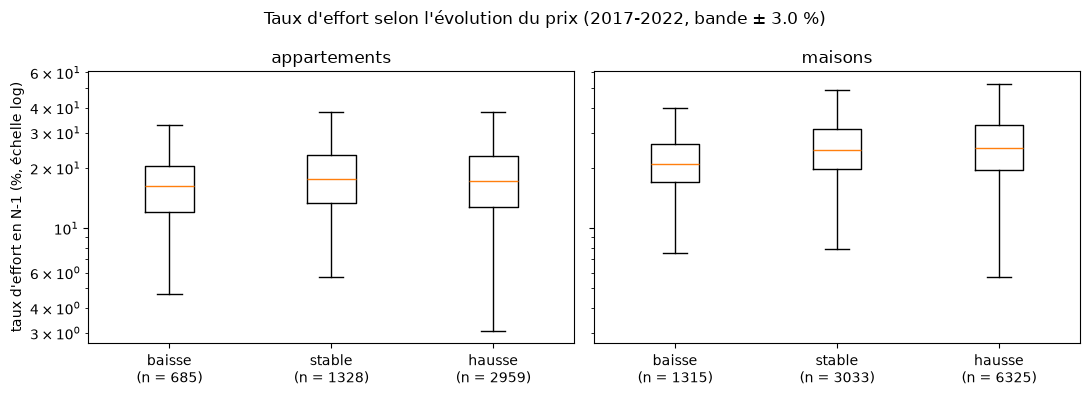

In [8]:
# Figure : distribution du taux d'effort par groupe (années 2017 à 2022, bande de BANDE_STABLE %)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, type_bien in zip(axes, TYPES):
    e = eda[eda["type_bien"] == type_bien]
    donnees = []
    etiquettes = []
    for g in GROUPES:
        donnees.append(e.loc[e["groupe"] == g, "taux_effort"])
        etiquettes.append(g + "\n(n = " + str((e["groupe"] == g).sum()) + ")")
    ax.boxplot(donnees, showfliers=False)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(etiquettes)
    ax.set_yscale("log")
    ax.set_title(type_bien + "s")
axes[0].set_ylabel("taux d'effort en N-1 (%, échelle log)")
fig.suptitle("Taux d'effort selon l'évolution du prix (2017-2022, bande ± " + str(BANDE_STABLE) + " %)")
plt.tight_layout()
plt.show()

### 2.5 Décision : le taux d'effort entre-t-il en modélisation ?
Règle fixée avant les résultats : l'indicateur **sépare** les groupes si, pour au moins un type de bien, la p-value de Kruskal-Wallis (taux d'effort, années réunies) est sous `SEUIL_P` **et** ε² atteint `SEUIL_EPSILON2`. Sinon, la section 4 ne se lance pas (feuille de route).

In [9]:
separe = {}
for type_bien in TYPES:
    r = kw_global[(kw_global["type de bien"] == type_bien) & (kw_global["variable"] == "taux_effort")].iloc[0]
    separe[type_bien] = bool((r["p-value"] < SEUIL_P) and (r["epsilon²"] >= SEUIL_EPSILON2))
    print(type_bien, ": epsilon² =", round(r["epsilon²"], 4), "| p-value =", r["p-value"],
          "| sépare les groupes :", separe[type_bien])

MODELISER = any(separe.values()) or FORCER_MODELISATION
print("Entrée en modélisation :", MODELISER)

appartement : epsilon² = 0.0061 | p-value = 1.0646361369267476e-07 | sépare les groupes : False
maison : epsilon² = 0.0187 | p-value = 2.1148470793933337e-44 | sépare les groupes : True
Entrée en modélisation : True


**Comment lire :** pour les maisons, ε² = 0,019 : le groupe (baisse, stable, hausse) explique 1,9 % des différences de rang du taux d'effort. C'est un effet petit. Les maisons en baisse ont un taux d'effort médian de 20,8 %, contre 25,0 % pour celles en hausse.

**Constat (bande de ±3 %, fixée dans H5) :**
- **Lecture par année** (les classes suivent la conjoncture : en 2021-2022, très peu de baisses).
  - Maisons : effet petit mais présent chaque année (ε² de 0,017 à 0,036, p < 0,001). Il reste présent sans la part commune (0,017).
  - Appartements : effet négligeable (ε² = 0,006 toutes années réunies). Il est sous 0,01 quatre années sur six, et nul en 2017 et 2020 (p > 0,05).
- **Le résultat ne dépend pas de la bande :** ε² de 0,018 à 0,020 pour les maisons entre 1 et 5 %.
- **Le sens est l'inverse de l'intuition, et c'est la baisse qui se distingue.** Les territoires en baisse sont les plus accessibles (rang-bisériale baisse contre hausse : −0,24 pour les maisons, −0,12 pour les appartements). Stables et hausses ne diffèrent pas (p corrigée de 0,15 et 0,23). De 2017 à 2022, la hausse est portée par les territoires chers. Les baisses viennent surtout de petits marchés bon marché, où la médiane est bruitée (H5, section 2.1).
- **Le prix N-1 sépare mieux les groupes que le taux d'effort**, chaque année (maisons : 0,031 contre 0,019 toutes années réunies). Pris seul, le taux d'effort ne dit rien que le prix N-1 ne dise déjà.

**Conclusion du constat rapide :** le taux d'effort passe la règle pour les maisons seulement : il entre en modélisation. Les résultats des appartements sont gardés pour documenter.

## 3. Fonctions du notebook
- `mesurer(nom, previsions_par_annee)` : passe les prévisions d'un modèle (un dictionnaire {année: prévisions}) dans `evaluer` et `tester` (contre la naïve), les garde pour la section 5.2 et affiche l'erreur. Relancer une cellule remplace les résultats du modèle au lieu de les ajouter une seconde fois.
- `regle_decision(res, tst, comparaison)` : la règle 1.5. Elle rend deux tableaux : le détail **année par année** (pour lire 2023 à part) et la décision (retenu si la majorité des années jugées sont réussies, ici les deux).
- `ModeleHierarchiquePente` : le modèle hiérarchique du gabarit P4, **étendu** à une pente aléatoire. Le gabarit de l'équipe n'a qu'une ordonnée aléatoire ; l'extension est faite ici, dans le notebook, pour ne pas modifier le fichier commun. Explication en 4.3.

In [10]:
resultats, tests, previsions = [], [], {}


def nom_complet(nom):
    return HYPOTHESE + " – " + nom


def mesurer(nom, previsions_par_annee):
    """Evaluer et tester contre la naïve un modèle déjà prévu : {année: Série de prévisions en €/m²}."""
    nom = nom_complet(nom)
    resultats[:] = [r for r in resultats if r["modèle"] != nom]
    tests[:] = [t for t in tests if t["modèle"] != nom]
    for annee in ANNEES:
        ev = FENETRES[annee][1]
        prevision = previsions_par_annee[annee].loc[ev.index]
        assert prevision.notna().all(), "prévision manquante"
        evaluer(nom, ev, prevision, resultats)
        tester(nom, ev, prevision, tests)
        previsions[(nom, annee)] = prevision
    res = pd.DataFrame(resultats)
    display(res.loc[res["modèle"] == nom, ["type de bien", "année jugée", "MAE (€/m²)", "MAE naïve (€/m²)",
                                            "gain sur la naïve (%)", "bassins où le modèle gagne (%)"]].round(1))
    return nom


def regle_decision(res, tst, comparaison="naïve"):
    """Règle 1.5 : détail par année et décision (retenu si la majorité des années est réussie)."""
    gain = "gain sur la " + comparaison + " (%)"
    cles = ["modèle", "type de bien", "année jugée"]
    detail = res[cles + [gain]].merge(tst[cles + ["IC 95 % haut (€/m²)", "rang-bisériale"]], on=cles)
    detail["année réussie"] = ((detail["IC 95 % haut (€/m²)"] < 0) & (detail["rang-bisériale"] < 0)
                               & (detail[gain] >= SEUIL_GAIN))
    decision = detail.groupby(["modèle", "type de bien"], sort=False)["année réussie"].agg(["sum", "count"])
    decision["retenu"] = decision["sum"] > decision["count"] / 2
    decision = decision.rename(columns={"sum": "années réussies", "count": "années jugées"})
    return detail, decision


class ModeleHierarchiquePente(ModeleHierarchique):
    """Gabarit P4 étendu : ordonnée aléatoire par sous-bassin, et pente aléatoire sur une variable si `pente` est donnée.

    log(prix) = b0 + b1*x1 + ... + bp*taux + u0_groupe + u1_groupe*taux + e
    - u0 : décalage propre au territoire (comme le gabarit P4) ;
    - u1 : écart du territoire à la pente moyenne bp (sa sensibilité propre au taux d'effort).
    pente=None : ordonnée aléatoire seule, comme le gabarit P4.
    Un territoire absent de l'apprentissage reçoit u0 = u1 = 0 (la moyenne).
    """

    def __init__(self, groupe="sous_bassin_de_vie", reml=True, pente=None):
        super().__init__(groupe=groupe, reml=reml)
        self.pente = pente

    def fit(self, X, y):
        # Même mise à l'échelle que le gabarit (sur l'apprentissage seulement)
        self.variables_ = list(X.columns)
        self.moyennes_ = X.mean()
        self.ecarts_ = X.std(ddof=0).replace(0, 1.0)
        exog = self._standardiser(X)
        # Colonnes des effets aléatoires : 1 (ordonnée), et la variable de la pente si demandée
        if self.pente is None:
            exog_re = np.ones((len(X), 1))
        else:
            exog_re = np.column_stack([np.ones(len(X)), exog[self.pente].to_numpy()])
        modele = MixedLM(endog=np.asarray(y), exog=exog.to_numpy(),
                         groups=np.asarray(self._etiquettes(X)), exog_re=exog_re)
        with warnings.catch_warnings(record=True) as avertissements:
            warnings.simplefilter("always")
            self.resultat_ = modele.fit(reml=self.reml)
        self.avertissements_ = [str(a.message) for a in avertissements]
        self.converge_ = bool(self.resultat_.converged)
        self.coefs_fixes_ = pd.Series(np.asarray(self.resultat_.fe_params), index=exog.columns)

        # Effets aléatoires de chaque territoire : [u0] ou [u0, u1]
        self.effets_aleatoires_ = {}
        for g, valeurs in self.resultat_.random_effects.items():
            self.effets_aleatoires_[g] = np.asarray(valeurs, dtype=float)

        # Variances : ordonnée, pente, résiduelle ; corrélation entre ordonnée et pente
        cov = np.asarray(self.resultat_.cov_re, dtype=float)
        self.variance_groupe_ = float(cov[0, 0])
        self.variance_residuelle_ = float(self.resultat_.scale)
        self.icc_ = self.variance_groupe_ / (self.variance_groupe_ + self.variance_residuelle_)
        self.variance_pente_ = np.nan
        self.correlation_ = np.nan
        if self.pente is not None:
            self.variance_pente_ = float(cov[1, 1])
            if cov[0, 0] > 0 and cov[1, 1] > 0:
                self.correlation_ = float(cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1]))
        self.log_vraisemblance_ = float(self.resultat_.llf)
        return self

    def predict(self, X):
        exog = self._standardiser(X)
        fixe = exog.to_numpy() @ self.coefs_fixes_.to_numpy()
        nb_effets = 1 if self.pente is None else 2
        u = np.array([self.effets_aleatoires_.get(g, np.zeros(nb_effets)) for g in self._etiquettes(X)])
        aleatoire = u[:, 0]
        if self.pente is not None:
            aleatoire = aleatoire + u[:, 1] * exog[self.pente].to_numpy()
        return pd.Series(fixe + aleatoire, index=X.index)


VARIABLES_HIERARCHIQUE = MODELE_COMPLET + BLOC       # mêmes variables que le modèle 2.1
LOG_HIERARCHIQUE = LOG + LOG_EN_PLUS                 # mêmes passages en log que le pont


def previsions_hierarchique(pente=None, modeles=None):
    """Prévisions du modèle hiérarchique pour chaque année jugée : {année: Série en €/m²}.

    Comme le pont : un modèle par type de bien, cible et variables asymétriques en log, apprentissage dès 2017.
    `modeles`, s'il est donné, est rempli avec {(année, type de bien): modèle ajusté}.
    """
    sortie = {}
    for annee in ANNEES:
        app, ev = FENETRES[annee]
        prevision = pd.Series(np.nan, index=ev.index)
        for type_bien, e in app.groupby("type_bien"):
            idx = ev.index[ev.index.get_level_values("type_bien") == type_bien]
            X_app = en_log(e[VARIABLES_HIERARCHIQUE], LOG_HIERARCHIQUE)
            X_ev = en_log(ev.loc[idx, VARIABLES_HIERARCHIQUE], LOG_HIERARCHIQUE)
            m = ModeleHierarchiquePente(pente=pente).fit(X_app, np.log(e[CIBLE]))
            prevision.loc[idx] = np.exp(m.predict(X_ev)).to_numpy()     # retour en €/m²
            if modeles is not None:
                modeles[(annee, type_bien)] = m
        sortie[annee] = prevision
    return sortie

## 4. Modèles
Tous les modèles sont gardés, y compris ceux qui perdent. Ils apprennent tous sur la période longue (dès 2017), comme le pont.

In [11]:
assert MODELISER, ("Le constat rapide (2.5) dit que le taux d'effort ne sépare pas les groupes : "
                   "pas de modélisation (feuille de route). Mettre FORCER_MODELISATION = True pour documenter quand même.")

### 4.1 Référence de l'hypothèse : le modèle pont
Relancé à l'identique avec le gabarit gabarit_pont.py. Ses MAE doivent être celles de H4 (appartements 158,7 en 2023 et 187,8 en 2024 ; maisons 130,4 et 180,2) : c'est le contrôle que le gabarit et la table sont les bons.

In [12]:
ajustes_pont = {}
PONT = mesurer("Modèle pont", previsions_pont(table, annees_jugees=ANNEES, modeles=ajustes_pont))

,type de bien,année jugée,MAE (€/m²),MAE naïve (€/m²),gain sur la naïve (%),bassins où le modèle gagne (%)
0,appartement,2023,158.7,166.3,4.6,55.7
1,maison,2023,130.4,111.7,-16.7,39.9
2,appartement,2024,187.8,148.0,-26.9,30.1
3,maison,2024,180.2,129.2,-39.5,23.3


### 4.2 Modèle 2.1 : pont + capacité d'achat
Le même Elastic Net, avec le taux d'effort (en log) en plus. Le réglage (alpha, l1_ratio) est refait sur les plis temporels. Si le taux d'effort n'apporte rien, l'Elastic Net peut ramener son coefficient à 0 : le modèle redevient alors le pont.

In [13]:
ajustes_capacite = {}
CAPACITE = mesurer("Pont + capacité d'achat",
                   previsions_pont(table, annees_jugees=ANNEES, bloc=BLOC, log_en_plus=LOG_EN_PLUS,
                                   modeles=ajustes_capacite))

,type de bien,année jugée,MAE (€/m²),MAE naïve (€/m²),gain sur la naïve (%),bassins où le modèle gagne (%)
4,appartement,2023,166.8,166.3,-0.3,56.4
5,maison,2023,123.5,111.7,-10.6,44.5
6,appartement,2024,162.8,148.0,-10.0,38.4
7,maison,2024,125.6,129.2,2.8,56.6


### 4.3 Modèle 2.2 : modèle hiérarchique avec une pente aléatoire sur la capacité d'achat
**L'idée.** Dans le modèle 2.1, le taux d'effort a **un seul coefficient**, le même partout : « +10 % de taux d'effort fait bouger le prix de x % », que l'on soit à Paris ou dans la Creuse. Le modèle hiérarchique laisse chaque territoire avoir **sa propre pente** :
- une **pente moyenne** (effet fixe), commune à tous ;
- un **écart à cette pente** pour chaque sous-bassin (effet aléatoire u1), tiré d'une loi normale de moyenne 0 et de variance σ²_pente.

Exemple : pente moyenne −0,05, σ_pente = 0,02. La plupart des territoires ont une pente entre −0,09 et −0,01 : tous sont freinés par un taux d'effort élevé, plus ou moins fort. Si σ_pente ≈ 0, tous les territoires réagissent de la même façon et la pente aléatoire n'apporte rien.

**Deux modèles**, pour isoler l'apport de la pente :
- **ordonnée seule** (gabarit P4) : un décalage par territoire, une pente commune ;
- **ordonnée + pente** : la question de H6.

Variables : celles du pont + taux d'effort, mêmes log, cible en log. Pas de réglage (le modèle hiérarchique n'a pas d'hyperparamètre). Durée : quelques minutes (8 ajustements).

In [14]:
ajustes_ordonnee = {}
HIER_ORDONNEE = mesurer("Hiérarchique – ordonnée seule",
                        previsions_hierarchique(pente=None, modeles=ajustes_ordonnee))

,type de bien,année jugée,MAE (€/m²),MAE naïve (€/m²),gain sur la naïve (%),bassins où le modèle gagne (%)
8,appartement,2023,169.7,166.3,-2.0,55.1
9,maison,2023,123.3,111.7,-10.4,44.9
10,appartement,2024,145.1,148.0,2.0,53.3
11,maison,2024,116.9,129.2,9.5,58.2


In [15]:
ajustes_pente = {}
HIER_PENTE = mesurer("Hiérarchique – pente aléatoire",
                     previsions_hierarchique(pente="taux_effort", modeles=ajustes_pente))

,type de bien,année jugée,MAE (€/m²),MAE naïve (€/m²),gain sur la naïve (%),bassins où le modèle gagne (%)
12,appartement,2023,166.5,166.3,-0.1,55.4
13,maison,2023,121.2,111.7,-8.5,46.5
14,appartement,2024,141.7,148.0,4.2,52.0
15,maison,2024,115.6,129.2,10.5,58.9


### 4.4 Modèle 2.3 (option) : gradient boosting (gabarit P3)
Le boosting peut trouver des effets que l'Elastic Net ne voit pas : un seuil (« au-delà de 35 % de taux d'effort, le prix décroche ») ou une interaction (« le taux d'effort ne compte que là où le parc est ancien »).

Pour une comparaison juste, sa référence est **le boosting sur les variables du pont** (même modèle, mêmes variables moins le taux d'effort, même période dès 2017). Comparer un boosting au pont Elastic Net mélangerait deux effets : celui du modèle et celui de la variable.

In [16]:
ajustes_boosting = {}
if LANCER_BOOSTING:
    prev_boosting_pont, prev_boosting_capacite = {}, {}
    for annee in ANNEES:
        app, ev = FENETRES[annee]
        prev_boosting_pont[annee], _ = prevoir_boosting(app, ev, MODELE_COMPLET)
        prev_boosting_capacite[annee], modeles = prevoir_boosting(app, ev, MODELE_COMPLET + BLOC)
        for type_bien in modeles:
            ajustes_boosting[(annee, type_bien)] = modeles[type_bien]
    BOOSTING_PONT = mesurer("Boosting – variables du pont", prev_boosting_pont)
    BOOSTING_CAPACITE = mesurer("Boosting – pont + capacité d'achat", prev_boosting_capacite)

,type de bien,année jugée,MAE (€/m²),MAE naïve (€/m²),gain sur la naïve (%),bassins où le modèle gagne (%)
16,appartement,2023,168.8,166.3,-1.5,54.4
17,maison,2023,140.5,111.7,-25.8,39.2
18,appartement,2024,201.8,148.0,-36.4,30.0
19,maison,2024,189.0,129.2,-46.3,24.8


,type de bien,année jugée,MAE (€/m²),MAE naïve (€/m²),gain sur la naïve (%),bassins où le modèle gagne (%)
20,appartement,2023,165.7,166.3,0.4,56.0
21,maison,2023,134.2,111.7,-20.2,40.4
22,appartement,2024,176.2,148.0,-19.1,40.1
23,maison,2024,166.4,129.2,-28.8,30.9


### 4.5 Sensibilité : indicatrice des prix 2021-2022 (H5)
H5 a montré qu'une indicatrice des prix 2021 et 2022 (le sommet de la hausse) bat nettement le pont et absorbe le gain du bloc H5. On vérifie si elle absorbe aussi celui du taux d'effort : on compare le pont + indicatrice + taux d'effort au pont + indicatrice. L'indicatrice vaut 0 sur les années jugées : elle ne sert qu'à l'apprentissage.

In [17]:
# 4.5 Sensibilité : indicatrice des prix 2021-2022 (H5)
# L'indicatrice vaut 1 pour les prix 2021 et 2022 (sommet de la hausse), 0 sinon.
# Elle vaut 0 sur les années jugées : elle ne sert qu'à l'apprentissage.
table_conf = table.copy()
table_conf["confinement"] = table_conf["annee"].isin([2021, 2022]).astype(float)

ajustes_pont_conf = {}
PONT_CONF = mesurer("Pont + indicatrice 2021-2022",
                    previsions_pont(table_conf, annees_jugees=ANNEES, bloc=["confinement"],
                                    modeles=ajustes_pont_conf))

ajustes_capacite_conf = {}
CAPACITE_CONF = mesurer("Pont + indicatrice 2021-2022 + capacité d'achat",
                        previsions_pont(table_conf, annees_jugees=ANNEES, bloc=["confinement"] + BLOC,
                                        log_en_plus=LOG_EN_PLUS, modeles=ajustes_capacite_conf))

,type de bien,année jugée,MAE (€/m²),MAE naïve (€/m²),gain sur la naïve (%),bassins où le modèle gagne (%)
24,appartement,2023,155.6,166.3,6.5,59.3
25,maison,2023,111.1,111.7,0.5,50.4
26,appartement,2024,162.0,148.0,-9.5,37.5
27,maison,2024,144.8,129.2,-12.1,35.9


,type de bien,année jugée,MAE (€/m²),MAE naïve (€/m²),gain sur la naïve (%),bassins où le modèle gagne (%)
28,appartement,2023,158.8,166.3,4.5,58.5
29,maison,2023,112.4,111.7,-0.6,50.2
30,appartement,2024,159.4,148.0,-7.7,42.5
31,maison,2024,130.1,129.2,-0.7,52.3


## 5. Mesures et tests
### 5.1 Contre la naïve
Mêmes tableaux que le template :
- **`res`** : MAE du modèle et de la naïve (€/m²), gain sur la naïve (%), part des sous-bassins où le modèle gagne ;
- **`tst`** : écart de MAE avec la naïve, son intervalle de confiance à 95 % (bootstrap par bassin de vie), p-value de Wilcoxon et rang-bisériale ;
- **règle 1.5** : une année est réussie si l'IC est entièrement sous 0, la rang-bisériale négative et le gain d'au moins 3 % ; un modèle est retenu s'il réussit la majorité des années (ici, les deux).

In [18]:
res = pd.DataFrame(resultats)
tst = pd.DataFrame(tests)
display(res.round(1))
display(tst.round(3))

,modèle,type de bien,année jugée,MAE (€/m²),MAE en % du prix,MAE naïve (€/m²),gain sur la naïve (%),bassins où le modèle gagne (%)
0,H6 – Modèle pont,appartement,2023,158.7,6.0,166.3,4.6,55.7
1,H6 – Modèle pont,maison,2023,130.4,5.9,111.7,-16.7,39.9
2,H6 – Modèle pont,appartement,2024,187.8,7.2,148.0,-26.9,30.1
3,H6 – Modèle pont,maison,2024,180.2,7.9,129.2,-39.5,23.3
4,H6 – Pont + capacité d'achat,appartement,2023,166.8,6.0,166.3,-0.3,56.4
5,H6 – Pont + capacité d'achat,maison,2023,123.5,5.4,111.7,-10.6,44.5
6,H6 – Pont + capacité d'achat,appartement,2024,162.8,6.2,148.0,-10.0,38.4
7,H6 – Pont + capacité d'achat,maison,2024,125.6,5.7,129.2,2.8,56.6
8,H6 – Hiérarchique – ordonnée seule,appartement,2023,169.7,6.0,166.3,-2.0,55.1
9,H6 – Hiérarchique – ordonnée seule,maison,2023,123.3,5.4,111.7,-10.4,44.9


,modèle,type de bien,année jugée,écart de MAE avec la naïve (€/m²),IC 95 % bas (€/m²),IC 95 % haut (€/m²),p-value Wilcoxon,rang-bisériale,bassins de vie
0,H6 – Modèle pont,appartement,2023,-7.643,-20.238,6.245,0.036,-0.083,726
1,H6 – Modèle pont,maison,2023,18.679,13.172,23.591,0.000,0.255,1606
2,H6 – Modèle pont,appartement,2024,39.817,32.287,46.767,0.000,0.465,692
3,H6 – Modèle pont,maison,2024,51.025,47.049,55.009,0.000,0.678,1605
4,H6 – Pont + capacité d'achat,appartement,2023,0.503,-14.450,20.952,0.004,-0.114,726
5,H6 – Pont + capacité d'achat,maison,2023,11.840,7.605,15.660,0.000,0.155,1606
6,H6 – Pont + capacité d'achat,appartement,2024,14.839,9.906,19.412,0.000,0.264,692
7,H6 – Pont + capacité d'achat,maison,2024,-3.560,-6.760,-0.310,0.000,-0.168,1605
8,H6 – Hiérarchique – ordonnée seule,appartement,2023,3.329,-11.937,24.970,0.009,-0.102,726
9,H6 – Hiérarchique – ordonnée seule,maison,2023,11.600,7.423,15.375,0.000,0.153,1606


In [19]:
detail_naive, decision_naive = regle_decision(res, tst)
display(detail_naive.sort_values(["année jugée", "type de bien"]).round(2))
decision_naive

,modèle,type de bien,année jugée,gain sur la naïve (%),IC 95 % haut (€/m²),rang-bisériale,année réussie
0,H6 – Modèle pont,appartement,2023,4.60,6.25,-0.08,False
4,H6 – Pont + capacité d'achat,appartement,2023,-0.30,20.95,-0.11,False
8,H6 – Hiérarchique – ordonnée seule,appartement,2023,-2.00,24.97,-0.10,False
12,H6 – Hiérarchique – pente aléatoire,appartement,2023,-0.11,14.64,-0.11,False
16,H6 – Boosting – variables du pont,appartement,2023,-1.51,26.28,-0.03,False
20,H6 – Boosting – pont + capacité d'achat,appartement,2023,0.37,23.47,-0.08,False
24,H6 – Pont + indicatrice 2021-2022,appartement,2023,6.46,-6.65,-0.24,True
28,H6 – Pont + indicatrice 2021-2022 + capacité d...,appartement,2023,4.52,-3.16,-0.21,True
1,H6 – Modèle pont,maison,2023,-16.72,23.59,0.26,False
5,H6 – Pont + capacité d'achat,maison,2023,-10.60,15.66,0.16,False


années réussies  années jugées  retenu
modèle                                             type de bien                                        
H6 – Modèle pont                                   appartement                 0              2   False
                                                   maison                      0              2   False
H6 – Pont + capacité d'achat                       appartement                 0              2   False
                                                   maison                      0              2   False
H6 – Hiérarchique – ordonnée seule                 appartement                 0              2   False
                                                   maison                      1              2   False
H6 – Hiérarchique – pente aléatoire                appartement                 0              2   False
                                                   maison                      1              2   False
H6 – Boosting – variables du pont                  appartement                 0              2   False
                                                   maison                      0              2   False
H6 – Boosting – pont + capacité d'achat            appartement                 0              2   False
                                                   maison                      0              2   False
H6 – Pont + indicatrice 2021-2022                  appartement                 1              2   False
                                                   maison                      0              2   False
H6 – Pont + indicatrice 2021-2022 + capacité d'... appartement                 1              2   False
                                                   maison                      0              2   False

**Résultats contre la naïve :** aucun modèle n'est retenu. Trois années seulement sont réussies : le hiérarchique (ordonnée seule et pente aléatoire) pour les maisons en 2024 (+9,5 % et +10,5 %), et le pont + indicatrice 2021-2022, avec ou sans taux d'effort, pour les appartements en 2023 (+6,5 % et +4,5 %). En 2023, tous les modèles sans indicatrice perdent contre la naïve pour les maisons (−8,5 % à −25,8 %). Avec l'indicatrice, ils font jeu égal (+0,5 % et −0,6 %).

### 5.2 La capacité d'achat apporte-t-elle quelque chose au modèle pont ?
La question propre à H6. Mêmes mesures et même règle, en remplaçant la naïve par la prévision de la référence : `evaluer` et `tester` lisent la prévision de comparaison dans la colonne `prix_n1`, on leur donne donc une copie de l'année jugée où cette colonne contient la prévision de la référence.

Les comparaisons :

| Modèle | Référence | Ce qu'on mesure |
|---|---|---|
| Pont + capacité d'achat (2.1) | Modèle pont | l'apport du taux d'effort |
| Hiérarchique, pente aléatoire (2.2) | Modèle pont | la question de la feuille de route |
| Hiérarchique, pente aléatoire | Hiérarchique, ordonnée seule | l'apport de la pente seule |
| Boosting + capacité d'achat (2.3) | Boosting, variables du pont | l'apport du taux d'effort dans un boosting |
| Boosting + capacité d'achat | Modèle pont | le boosting bat-il la référence de l'hypothèse ? |
| Pont + indicatrice 2021-2022 | Modèle pont | l'apport de l'indicatrice (H5) |
| Pont + indicatrice + capacité d'achat | Pont + indicatrice | l'apport du taux d'effort quand le pont a l'indicatrice |

**2023 lu à part.** La règle dit « majorité des années ». Avec deux années jugées, il faut réussir les deux. Mais 2023 et 2024 ne racontent pas la même chose : en 2023, les taux de crédit ont commencé à monter (2,05 % en décembre 2022) mais les prix résistaient encore ; en 2024, les taux sont à 3,63 % et les prix baissent. Un indicateur de capacité d'achat devrait surtout aider en 2024. Le détail année par année est donc lu ligne par ligne.

In [20]:
COMPARAISONS = [(CAPACITE, PONT), (HIER_PENTE, PONT), (HIER_PENTE, HIER_ORDONNEE)]
if LANCER_BOOSTING:
    COMPARAISONS = COMPARAISONS + [(BOOSTING_CAPACITE, BOOSTING_PONT), (BOOSTING_CAPACITE, PONT)]

# Sensibilité : le taux d'effort apporte-t-il encore quelque chose quand le pont a l'indicatrice ?
COMPARAISONS = COMPARAISONS + [(PONT_CONF, PONT), (CAPACITE_CONF, PONT_CONF)]

def court(nom):
    """Nom sans le préfixe de l'hypothèse."""
    return nom.replace(HYPOTHESE + " – ", "")


def vers_reference(colonne):
    return colonne.replace("naïve", "référence")


resultats_ref, tests_ref = [], []
for nom, nom_ref in COMPARAISONS:
    etiquette = court(nom) + "  |  contre : " + court(nom_ref)
    for annee in ANNEES:
        ev_ref = FENETRES[annee][1].copy()
        ev_ref["prix_n1"] = previsions[(nom_ref, annee)]          # la comparaison se fait avec la référence
        evaluer(etiquette, ev_ref, previsions[(nom, annee)], resultats_ref)
        tester(etiquette, ev_ref, previsions[(nom, annee)], tests_ref)

res_ref = pd.DataFrame(resultats_ref).rename(columns=vers_reference)
tst_ref = pd.DataFrame(tests_ref).rename(columns=vers_reference)
display(res_ref[["modèle", "type de bien", "année jugée", "MAE (€/m²)", "MAE référence (€/m²)",
                 "gain sur la référence (%)", "bassins où le modèle gagne (%)"]].round(2))
display(tst_ref[["modèle", "type de bien", "année jugée", "écart de MAE avec la référence (€/m²)",
                 "IC 95 % bas (€/m²)", "IC 95 % haut (€/m²)", "p-value Wilcoxon", "rang-bisériale"]].round(3))

,modèle,type de bien,année jugée,MAE (€/m²),MAE référence (€/m²),gain sur la référence (%),bassins où le modèle gagne (%)
0,Pont + capacité d'achat | contre : Modèle pont,appartement,2023,166.83,158.68,-5.13,51.45
1,Pont + capacité d'achat | contre : Modèle pont,maison,2023,123.55,130.39,5.25,62.81
2,Pont + capacité d'achat | contre : Modèle pont,appartement,2024,162.84,187.82,13.30,73.63
3,Pont + capacité d'achat | contre : Modèle pont,maison,2024,125.63,180.21,30.29,73.59
4,Hiérarchique – pente aléatoire | contre : Mo...,appartement,2023,166.51,158.68,-4.93,47.85
5,Hiérarchique – pente aléatoire | contre : Mo...,maison,2023,121.16,130.39,7.08,63.82
6,Hiérarchique – pente aléatoire | contre : Mo...,appartement,2024,141.74,187.82,24.53,61.60
7,Hiérarchique – pente aléatoire | contre : Mo...,maison,2024,115.64,180.21,35.83,70.27
8,Hiérarchique – pente aléatoire | contre : Hi...,appartement,2023,166.51,169.65,1.85,45.06
9,Hiérarchique – pente aléatoire | contre : Hi...,maison,2023,121.16,123.31,1.74,61.29


,modèle,type de bien,année jugée,écart de MAE avec la référence (€/m²),IC 95 % bas (€/m²),IC 95 % haut (€/m²),p-value Wilcoxon,rang-bisériale
0,Pont + capacité d'achat | contre : Modèle pont,appartement,2023,8.146,1.120,17.148,0.836,0.008
1,Pont + capacité d'achat | contre : Modèle pont,maison,2023,-6.839,-9.892,-3.374,0.000,-0.287
2,Pont + capacité d'achat | contre : Modèle pont,appartement,2024,-24.978,-28.774,-20.759,0.000,-0.535
3,Pont + capacité d'achat | contre : Modèle pont,maison,2024,-54.585,-59.538,-49.362,0.000,-0.619
4,Hiérarchique – pente aléatoire | contre : Mo...,appartement,2023,7.830,2.603,13.276,0.038,0.081
5,Hiérarchique – pente aléatoire | contre : Mo...,maison,2023,-9.227,-12.180,-6.274,0.000,-0.299
6,Hiérarchique – pente aléatoire | contre : Mo...,appartement,2024,-46.079,-66.256,-27.787,0.000,-0.328
7,Hiérarchique – pente aléatoire | contre : Mo...,maison,2024,-64.570,-70.565,-58.724,0.000,-0.574
8,Hiérarchique – pente aléatoire | contre : Hi...,appartement,2023,-3.142,-11.438,3.275,0.008,0.104
9,Hiérarchique – pente aléatoire | contre : Hi...,maison,2023,-2.148,-4.331,0.537,0.000,-0.262


In [21]:
detail_ref, decision_ref = regle_decision(res_ref, tst_ref, comparaison="référence")
print("Année par année (2023 lu à part) :")
for annee in ANNEES:
    print("\nAnnée jugée", annee)
    display(detail_ref[detail_ref["année jugée"] == annee].drop(columns="année jugée").round(2))
print("\nDécision (majorité des années) :")
decision_ref

Année par année (2023 lu à part) :

Année jugée 2023


,modèle,type de bien,gain sur la référence (%),IC 95 % haut (€/m²),rang-bisériale,année réussie
0,Pont + capacité d'achat | contre : Modèle pont,appartement,-5.13,17.15,0.01,False
1,Pont + capacité d'achat | contre : Modèle pont,maison,5.25,-3.37,-0.29,True
4,Hiérarchique – pente aléatoire | contre : Mo...,appartement,-4.93,13.28,0.08,False
5,Hiérarchique – pente aléatoire | contre : Mo...,maison,7.08,-6.27,-0.30,True
8,Hiérarchique – pente aléatoire | contre : Hi...,appartement,1.85,3.28,0.10,False
9,Hiérarchique – pente aléatoire | contre : Hi...,maison,1.74,0.54,-0.26,False
12,Boosting – pont + capacité d'achat | contre ...,appartement,1.86,-0.78,-0.12,False
13,Boosting – pont + capacité d'achat | contre ...,maison,4.47,-5.28,-0.33,True
16,Boosting – pont + capacité d'achat | contre ...,appartement,-4.42,18.29,0.11,False
17,Boosting – pont + capacité d'achat | contre ...,maison,-2.94,5.90,0.11,False



Année jugée 2024


,modèle,type de bien,gain sur la référence (%),IC 95 % haut (€/m²),rang-bisériale,année réussie
2,Pont + capacité d'achat | contre : Modèle pont,appartement,13.30,-20.76,-0.54,True
3,Pont + capacité d'achat | contre : Modèle pont,maison,30.29,-49.36,-0.62,True
6,Hiérarchique – pente aléatoire | contre : Mo...,appartement,24.53,-27.79,-0.33,True
7,Hiérarchique – pente aléatoire | contre : Mo...,maison,35.83,-58.72,-0.57,True
10,Hiérarchique – pente aléatoire | contre : Hi...,appartement,2.30,8.11,0.03,False
11,Hiérarchique – pente aléatoire | contre : Hi...,maison,1.12,0.92,-0.06,False
14,Boosting – pont + capacité d'achat | contre ...,appartement,12.67,-17.49,-0.46,True
15,Boosting – pont + capacité d'achat | contre ...,maison,11.99,-20.47,-0.52,True
18,Boosting – pont + capacité d'achat | contre ...,appartement,6.16,-7.19,-0.25,True
19,Boosting – pont + capacité d'achat | contre ...,maison,7.67,-10.81,-0.33,True



Décision (majorité des années) :


années réussies  années jugées  retenu
modèle                                             type de bien                                        
Pont + capacité d'achat  |  contre : Modèle pont   appartement                 1              2   False
                                                   maison                      2              2    True
Hiérarchique – pente aléatoire  |  contre : Mod... appartement                 1              2   False
                                                   maison                      2              2    True
Hiérarchique – pente aléatoire  |  contre : Hié... appartement                 0              2   False
                                                   maison                      0              2   False
Boosting – pont + capacité d'achat  |  contre :... appartement                 1              2   False
                                                   maison                      2              2    True
Boosting – pont + capacité d'achat  |  contre :... appartement                 1              2   False
                                                   maison                      1              2   False
Pont + indicatrice 2021-2022  |  contre : Modèl... appartement                 1              2   False
                                                   maison                      2              2    True
Pont + indicatrice 2021-2022 + capacité d'achat... appartement                 0              2   False
                                                   maison                      1              2   False

**Comment lire :** pont + capacité d'achat, maisons 2024 : la MAE passe de 180,2 à 125,6 €/m² (gain de 30 %). L'IC de l'écart va de −59,5 à −49,4 €/m², entièrement sous 0, et la rang-bisériale vaut −0,62 : le modèle fait mieux que le pont dans 74 % des sous-bassins.

**Résultats contre le modèle pont :**
- **Maisons : la capacité d'achat améliore nettement le pont, avec les trois modèles.**
  - 2.1 : +5,3 % en 2023, +30 % en 2024 ;
  - 2.2 : +7,1 % en 2023, +36 % en 2024 ;
  - boosting contre boosting du pont : +4,5 % en 2023, +12 % en 2024.
  - Les trois sont retenus (2 années sur 2).
- **Appartements : non retenu.** Gros gain en 2024 (+13 % pour 2.1, +24 % pour 2.2), mais perte en 2023 (−5 %).
- **2023 lu à part :** l'apport est faible en 2023 (+5 à +7 % pour les maisons, négatif pour les appartements) et fort en 2024. C'est cohérent : le taux de crédit passe de 2,05 % à 3,63 %, et c'est en 2024 que les prix baissent.
- **La pente aléatoire seule n'apporte rien :** contre le hiérarchique à ordonnée seule, gain de 1 à 2 %, jamais retenu.
- **Le boosting + capacité d'achat ne bat pas le pont Elastic Net** (perte en 2023, gain de 6 à 8 % en 2024) : pas retenu.
- **Sensibilité à l'indicatrice 2021-2022 (4.5) :**
  - Le pont + indicatrice bat le pont : maisons +14,8 % puis +19,6 % (retenu), appartements +2,0 % puis +13,7 %. Mêmes résultats que H5.
  - Avec l'indicatrice dans le pont, le taux d'effort n'est plus retenu. Maisons : −1,1 % en 2023, mais **+10,2 % en 2024** (IC entièrement sous 0, rang-bisériale −0,54). Appartements : −2,1 % puis +1,6 %.
  - En 2023, l'indicatrice fait déjà tout le travail. En 2024, le taux d'effort garde un apport propre.

### 5.3 D'où vient la différence : biais ou classement des territoires ?
La leçon de H4 : le gain du pont venait de la **part commune** (le biais, le « quand »), pas du classement des territoires (le « où »). On refait la même décomposition :
- **biais** : erreur moyenne signée (positive : le modèle surestime) ;
- **MAE sans part commune** : l'erreur après avoir retiré le biais de l'année, ce qui reste quand le niveau moyen est juste. C'est la qualité du « où ».

Le taux d'effort contient le taux de crédit, commun à tous : on s'attend à ce qu'il agisse d'abord sur le biais. S'il baisse aussi la MAE sans part commune, le revenu du territoire (le « où ») apporte quelque chose.

In [22]:
lignes = []
for nom in dict.fromkeys(cle[0] for cle in previsions):       # chaque modèle une fois, dans l'ordre
    for annee in ANNEES:
        ev = FENETRES[annee][1]
        for type_bien in TYPES:
            e = ev[ev.index.get_level_values("type_bien") == type_bien]
            erreur = previsions[(nom, annee)].loc[e.index] - e[CIBLE]
            erreur_naive = e["prix_n1"] - e[CIBLE]
            lignes.append({"modèle": court(nom), "type de bien": type_bien, "année jugée": annee,
                           "MAE": erreur.abs().mean(), "biais": erreur.mean(),
                           "MAE sans part commune": (erreur - erreur.mean()).abs().mean(),
                           "MAE naïve": erreur_naive.abs().mean(), "biais naïve": erreur_naive.mean(),
                           "MAE naïve sans part commune": (erreur_naive - erreur_naive.mean()).abs().mean()})
decomposition = pd.DataFrame(lignes).sort_values(["type de bien", "année jugée"])
decomposition.round(1)

,modèle,type de bien,année jugée,MAE,biais,MAE sans part commune,MAE naïve,biais naïve,MAE naïve sans part commune
0,Modèle pont,appartement,2023,158.7,40.7,156.2,166.3,-64.5,156.2
4,Pont + capacité d'achat,appartement,2023,166.8,7.4,167.0,166.3,-64.5,156.2
8,Hiérarchique – ordonnée seule,appartement,2023,169.7,0.6,169.7,166.3,-64.5,156.2
12,Hiérarchique – pente aléatoire,appartement,2023,166.5,-11.2,165.8,166.3,-64.5,156.2
16,Boosting – variables du pont,appartement,2023,168.8,54.2,167.8,166.3,-64.5,156.2
20,Boosting – pont + capacité d'achat,appartement,2023,165.7,34.0,167.1,166.3,-64.5,156.2
24,Pont + indicatrice 2021-2022,appartement,2023,155.6,-24.5,154.0,166.3,-64.5,156.2
28,Pont + indicatrice 2021-2022 + capacité d'achat,appartement,2023,158.8,-34.4,156.3,166.3,-64.5,156.2
2,Modèle pont,appartement,2024,187.8,136.0,152.8,148.0,40.7,145.1
6,Pont + capacité d'achat,appartement,2024,162.8,86.1,148.2,148.0,40.7,145.1


**Comment lire :** maisons 2024 : le pont surestime de 150,6 €/m² en moyenne ; avec le taux d’effort, il ne surestime plus que de 50,0 €/m². Sans la part commune, la MAE passe de 138,9 à 121,6 €/m².

**Constat :** l’essentiel du gain vient du biais, c’est-à-dire du « quand ». Le taux d’effort contient le taux de crédit, commun à tous les territoires : sa hausse en 2023-2024 dit au modèle que le marché va freiner. Le « où » s’améliore aussi un peu (maisons 2024 : 138,9 → 121,6), mais reste moins bon que celui de la naïve (118,2). Même leçon que H4 : les variables aident sur le niveau moyen de l’année, pas sur le classement des territoires.
Avec l'indicatrice 2021-2022, les deux corrections se répartissent les années. En 2023, l'indicatrice retire tout le biais des maisons (+72 → +0,2 €/m²). En 2024, elle n'en retire qu'un tiers (+151 → +98), et le taux d'effort ajouté descend le biais à +69 €/m². En 2024, le taux d'effort seul fait mieux que l'indicatrice seule (125,6 contre 144,8 €/m²).

## 6. Interprétation
### 6.1 Contexte : le marché, les taux de crédit et le taux d'effort
Évolution médiane du prix et taux d'effort médian par année, jusqu'à 2024 (2025 n'est pas regardé), avec le taux de crédit de décembre N-1 (P7).

Point d'attention : de 2017 à 2022, le taux de crédit reste entre 1,1 et 1,6 %. En 2023 (2,05 %) et surtout en 2024 (3,63 %), il sort de tout ce que les modèles ont vu à l'apprentissage. Un modèle linéaire **prolonge** sa pente au-delà de ce qu'il a vu (extrapolation) ; un boosting **plafonne** à la dernière valeur connue. Les deux peuvent se tromper, dans des sens différents.

In [23]:
capacite = pd.read_parquet(commun.DATA_OUT / "fe_capacite_achat_sbv.parquet")
capacite = capacite[capacite["annee"] <= commun.ANNEE_VALIDATION]
taux_credit = capacite.groupby("annee")["taux_credit"].median()

jusqua_2024 = table[(table["annee"] >= ANNEE_DEBUT_PONT) & (table["annee"] <= commun.ANNEE_VALIDATION)]
cles = [jusqua_2024["annee"], jusqua_2024.index.get_level_values("type_bien")]
contexte = pd.DataFrame({
    "évolution médiane (%)": ((jusqua_2024[CIBLE] / jusqua_2024["prix_n1"] - 1) * 100).groupby(cles).median(),
    "taux d'effort médian (%)": jusqua_2024["taux_effort"].groupby(cles).median(),
}).unstack()
contexte["taux de crédit déc. N-1 (%)"] = taux_credit
contexte.round(2)

évolution médiane (%)        taux d'effort médian (%)        taux de crédit déc. N-1 (%)
type_bien           appartement maison              appartement maison                            
annee                                                                                             
2017                       2.13   1.97                    17.76  23.89                        1.50
2018                       1.50   2.13                    17.88  24.48                        1.61
2019                       2.98   2.28                    17.17  24.43                        1.49
2020                       5.06   4.73                    16.47  23.58                        1.17
2021                       7.52   7.70                    16.77  24.12                        1.24
2022                       8.19   9.09                    17.28  25.35                        1.10
2023                       2.86   0.78                    21.10  30.20                        2.05
2024                      -1.48  -2.85                    25.02  35.09                        3.63

### 6.2 Le coefficient du taux d'effort dans le modèle 2.1
Coefficients standardisés : effet sur le log du prix d'une hausse d'un écart-type de la variable (en log), toutes les autres variables fixées. Exemple : −0,02 veut dire qu'un territoire dont le taux d'effort est plus haut d'un écart-type a, à prix N-1 et parc égaux, un prix prévu environ 2 % plus bas.

Lecture attendue : **négatif**. À prix N-1 égal, un taux d'effort plus haut veut dire un crédit plus cher ou des revenus plus faibles, donc moins d'acheteurs solvables. Un coefficient à 0 : l'Elastic Net a écarté la variable. On compare aussi le coefficient du prix N-1 avec et sans le taux d'effort : comme les deux variables se recouvrent en partie (section 2.1), l'ajout de l'une peut déplacer l'autre.

In [24]:
lignes = []
for annee in ANNEES:
    for type_bien in TYPES:
        m = ajustes_capacite[(annee, type_bien)]
        m_pont = ajustes_pont[(annee, type_bien)]
        lignes.append({"année jugée": annee, "type de bien": type_bien,
                       "coef. taux d'effort": m.coefs_["taux_effort"],
                       "coef. prix N-1 (avec)": m.coefs_["prix_n1"],
                       "coef. prix N-1 (pont)": m_pont.coefs_["prix_n1"],
                       "alpha": m.reglage_["alpha"], "l1_ratio": m.reglage_["l1_ratio"],
                       "alpha (pont)": m_pont.reglage_["alpha"]})
pd.DataFrame(lignes).round(4)

,année jugée,type de bien,coef. taux d'effort,coef. prix N-1 (avec),coef. prix N-1 (pont),alpha,l1_ratio,alpha (pont)
0,2023,appartement,-0.0780,0.5766,0.5138,0.0003,0.8,0.0032
1,2023,maison,-0.0917,0.5297,0.4462,0.0000,0.2,0.0010
2,2024,appartement,-0.0377,0.5442,0.5155,0.0010,0.8,0.0032
3,2024,maison,-0.0917,0.5323,0.4439,0.0000,0.2,0.0003


### 6.3 La pente aléatoire : les territoires réagissent-ils différemment ?
Pour chaque fenêtre et type de bien :
- **pente moyenne** : coefficient fixe du taux d'effort (standardisé, en log) ;
- **variance de la pente** (σ²_pente) et son écart-type σ_pente : la dispersion des sensibilités entre territoires ;
- **part des territoires à pente de signe opposé** : parmi les territoires de l'apprentissage, part dont la pente propre (pente moyenne + u1) n'a pas le signe de la pente moyenne ;
- **corrélation ordonnée-pente** : par exemple, négative si les territoires plus chers que prévu sont aussi les plus sensibles au taux d'effort ;
- **test du rapport de vraisemblance** (pente contre ordonnée seule) : la pente aléatoire améliore-t-elle l'ajustement ? La variance testée ne peut pas être négative : la p-value utilise le mélange de lois du χ² habituel dans ce cas (moitié χ² à 1 degré, moitié χ² à 2 degrés) ;
- **convergence** : si l'ajustement n'a pas convergé, la variance est souvent collée à 0 (même difficulté que l'ICC du gabarit P4).

In [25]:
lignes = []
for annee in ANNEES:
    for type_bien in TYPES:
        m = ajustes_pente[(annee, type_bien)]
        m0 = ajustes_ordonnee[(annee, type_bien)]
        pente_moyenne = m.coefs_fixes_["taux_effort"]
        pentes_propres = []
        for g in m.effets_aleatoires_:
            pentes_propres.append(pente_moyenne + m.effets_aleatoires_[g][1])
        pentes_propres = np.array(pentes_propres)
        rapport = max(2 * (m.log_vraisemblance_ - m0.log_vraisemblance_), 0)
        p_value = 0.5 * stats.chi2.sf(rapport, 1) + 0.5 * stats.chi2.sf(rapport, 2)
        lignes.append({"année jugée": annee, "type de bien": type_bien,
                       "pente moyenne": pente_moyenne,
                       "variance pente": m.variance_pente_, "écart-type pente": np.sqrt(m.variance_pente_),
                       "part pentes de signe opposé (%)": (np.sign(pentes_propres) != np.sign(pente_moyenne)).mean() * 100,
                       "corrélation ordonnée-pente": m.correlation_,
                       "variance ordonnée": m.variance_groupe_, "variance résiduelle": m.variance_residuelle_,
                       "ICC (ordonnée seule)": m0.icc_,
                       "rapport de vraisemblance": rapport, "p-value": p_value,
                       "convergé": m.converge_, "convergé (ordonnée seule)": m0.converge_,
                       "territoires inconnus à l'évaluation (%)": m.part_groupes_inconnus(
                           FENETRES[annee][1][FENETRES[annee][1].index.get_level_values("type_bien") == type_bien]) * 100})
pente_aleatoire = pd.DataFrame(lignes)
pente_aleatoire.round(5)

,année jugée,type de bien,pente moyenne,variance pente,écart-type pente,part pentes de signe opposé (%),corrélation ordonnée-pente,variance ordonnée,variance résiduelle,ICC (ordonnée seule),rapport de vraisemblance,p-value,convergé,convergé (ordonnée seule),territoires inconnus à l'évaluation (%)
0,2023,appartement,-0.12031,0.00063,0.02507,0.0,-0.99377,0.00000,0.00653,0.00233,0.00000,1.0,False,False,0.69686
1,2023,maison,-0.10624,0.00015,0.01244,0.0,-0.99520,0.00001,0.00504,0.00436,0.00000,1.0,False,False,0.05618
2,2024,appartement,-0.13396,0.00112,0.03351,0.0,-0.44977,0.00032,0.00627,0.01932,0.00000,1.0,True,False,0.24301
3,2024,maison,-0.12012,0.00016,0.01274,0.0,0.99964,0.00006,0.00491,0.05290,221.81086,0.0,True,True,0.00000


**Comment lire :** maisons 2024 : pente moyenne −0,12, écart-type de la pente 0,013. Tous les territoires ont une pente du même signe (0 % de signe opposé) : un taux d’effort plus élevé freine le prix partout, avec la même force à peu près.

**Constat :**
- **La variance de la pente est presque nulle** (écart-type de 0,012 à 0,037, pour une pente moyenne de −0,11 à −0,13).
- Le test du rapport de vraisemblance ne voit aucun apport dans 3 cas sur 4 (p = 1).
- Le 4e cas (maisons 2024, p < 0,001) n'est pas fiable : la corrélation ordonnée-pente vaut 0,9996. Une corrélation de ±0,99 (comme dans les autres cas) est le signe d'une estimation coincée à la limite, pas d'un vrai effet.
- Le hiérarchique à ordonnée seule n'a pas convergé pour les appartements 2024 : ce résultat est à lire avec prudence.
- **Conclusion :** les territoires réagissent tous de la même façon à la capacité d'achat. Une pente commune suffit.

### 6.4 Où le taux d'effort aide-t-il ? (modèle 2.1 contre le pont, par quartile de taux d'effort)
On range les territoires de l'année jugée en quatre quartiles de taux d'effort (Q1 : les plus accessibles, Q4 : les moins accessibles). Dans chaque quartile : écart moyen |erreur 2.1| − |erreur pont| (négatif : le taux d'effort aide), et biais des deux modèles. Lecture métier attendue : l'apport, s'il existe, devrait se voir dans Q4, là où les acheteurs sont le plus contraints.

In [26]:
lignes = []
for annee in ANNEES:
    ev = FENETRES[annee][1]
    for type_bien in TYPES:
        e = ev[ev.index.get_level_values("type_bien") == type_bien]
        quartile = pd.qcut(e["taux_effort"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
        erreur_capacite = previsions[(CAPACITE, annee)].loc[e.index] - e[CIBLE]
        erreur_pont = previsions[(PONT, annee)].loc[e.index] - e[CIBLE]
        for q in ["Q1", "Q2", "Q3", "Q4"]:
            dans_q = quartile == q
            lignes.append({"année jugée": annee, "type de bien": type_bien, "quartile": q,
                           "taux d'effort médian (%)": e.loc[dans_q, "taux_effort"].median(),
                           "écart |2.1| − |pont| (€/m²)": (erreur_capacite[dans_q].abs() - erreur_pont[dans_q].abs()).mean(),
                           "biais 2.1 (€/m²)": erreur_capacite[dans_q].mean(),
                           "biais pont (€/m²)": erreur_pont[dans_q].mean(),
                           "lignes": int(dans_q.sum())})
pd.DataFrame(lignes).round(1)

,année jugée,type de bien,quartile,taux d'effort médian (%),écart |2.1| − |pont| (€/m²),biais 2.1 (€/m²),biais pont (€/m²),lignes
0,2023,appartement,Q1,12.6,-0.1,-9.9,5.0,216
1,2023,appartement,Q2,18.0,-0.4,-1.5,29.1,215
2,2023,appartement,Q3,23.7,-8.8,46.2,84.0,215
3,2023,appartement,Q4,36.1,41.9,-5.1,44.8,215
4,2023,maison,Q1,19.5,-2.2,-0.1,11.2,445
5,2023,maison,Q2,26.9,-10.5,33.8,60.7,445
6,2023,maison,Q3,34.7,-18.4,66.1,102.1,445
7,2023,maison,Q4,49.9,3.7,49.9,114.6,445
8,2024,appartement,Q1,14.7,-7.6,16.1,41.8,206
9,2024,appartement,Q2,21.7,-17.6,42.9,83.5,206


### 6.5 (option) Importance du taux d'effort dans le boosting
Importance par permutation sur l'année jugée : on mélange au hasard les valeurs d'une variable entre les sous-bassins, 10 fois, et on mesure de combien la MAE augmente. Une variable compte si la hausse dépasse nettement deux écarts-types.

In [27]:
if LANCER_BOOSTING:
    lignes = []
    for annee in ANNEES:
        ev = FENETRES[annee][1]
        for type_bien in TYPES:
            e = ev[ev.index.get_level_values("type_bien") == type_bien]
            X_ev = e[MODELE_COMPLET + BLOC]
            imp = permutation_importance(ajustes_boosting[(annee, type_bien)], X_ev, e[CIBLE],
                                         scoring="neg_mean_absolute_error", n_repeats=10,
                                         random_state=commun.GRAINE)
            importance = pd.Series(imp.importances_mean, index=X_ev.columns)
            ecart_type = pd.Series(imp.importances_std, index=X_ev.columns)
            lignes.append({"année jugée": annee, "type de bien": type_bien,
                           "hausse de MAE taux d'effort (€/m²)": importance["taux_effort"],
                           "écart-type (€/m²)": ecart_type["taux_effort"],
                           "rang du taux d'effort (sur " + str(len(importance)) + ")":
                               int((importance > importance["taux_effort"]).sum()) + 1,
                           "variable la plus importante": importance.idxmax()})
    display(pd.DataFrame(lignes).round(1))

,année jugée,type de bien,hausse de MAE taux d'effort (€/m²),écart-type (€/m²),rang du taux d'effort (sur 13),variable la plus importante
0,2023,appartement,63.4,3.8,2,prix_n1
1,2023,maison,61.1,2.4,2,prix_n1
2,2024,appartement,72.7,3.9,2,prix_n1
3,2024,maison,61.1,3.3,2,prix_n1


## 7. Conclusion

**Constat rapide :** avec la bande de ±3 % (H5), le taux d'effort sépare faiblement les territoires pour les maisons (ε² = 0,019, présent chaque année), pas pour les appartements (0,006). Ce sont surtout les territoires en baisse qui se distinguent, par un taux d'effort *plus bas*, et le prix N-1 sépare mieux que lui.

**Contre la naïve :** aucun modèle retenu. Les maisons perdent en 2023 avec tous les modèles.

**Contre le modèle pont (question de H6) :** oui pour les maisons. Ajouter le taux d'effort améliore le pont en 2023 (+5 %) et surtout en 2024 (+30 %). Les trois approches (2.1, 2.2, boosting contre son propre pont) sont retenues. Pour les appartements, l'apport est fort en 2024 (+13 %) mais négatif en 2023 : non retenu.

**Sensibilité à l'indicatrice 2021-2022 :** si le pont prend l'indicatrice de H5, le taux d'effort n'est plus retenu (maisons : −1,1 % en 2023, +10,2 % en 2024). Contrairement au bloc H5, il garde un apport propre en 2024 : l'indicatrice corrige le prolongement du sommet (2023), le taux d'effort porte la hausse du crédit (2024). **H6 doit être rejugé si l'équipe ajoute l'indicatrice au pont.**

**Par où passe l'effet :** surtout par le biais (le « quand »). Le taux d'effort porte la hausse des taux de crédit et corrige la surestimation du pont (maisons 2024 : de +151 à +50 €/m²). Le coefficient est négatif, comme attendu : à prix N-1 égal, un crédit plus cher ou des revenus plus faibles font baisser le prix prévu. Le gain est le plus fort là où acheter est le plus difficile (quartile Q4 des maisons 2024 : −111 €/m²). Mais c'est aussi là que les prix sont les plus élevés, et un même effet en % pèse plus en €/m².

**Pente aléatoire :** variance quasi nulle ; tous les territoires réagissent de la même façon. Le gain du modèle 2.2 vient du taux d'effort, pas de la pente.

**Conclusion métier :** la capacité d'achat est le premier bloc qui corrige le défaut principal du pont, la surestimation quand le marché se retourne. Elle le fait parce qu'elle contient le taux de crédit, un signal d'avance sur la conjoncture. En revanche, elle n'aide pas à classer les territoires entre eux et ne suffit pas à battre la naïve sur les deux années.

**Limites :** le gain repose sur un seul signal commun (la hausse des taux), observé une seule fois, avec des taux hors de la plage d'apprentissage. Le test 2025 (taux en baisse, 3,15 %) dira si l'effet tient dans l'autre sens. Surfaces de 60 et 100 m² fixées a priori ; revenus figés à 2021 ; lignes non indépendantes dans le test de Kruskal-Wallis.